# Customer Segmentation with Clustering
**Goal:** segment a set of wholesale customers into groups using k-means, decide how many
groups with the **elbow method** and the **silhouette score**, and explain what each segment is.



## Your dataset

Use the **Wholesale Customers** dataset: annual spending (monetary units) by 440 clients of a
wholesale distributor across product categories.

- Download: [UCI Wholesale Customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers) (also searchable as "Wholesale customers" on Kaggle).
- Columns: `Channel`, `Region` (these are labels, not spending), then the six spend columns `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.
- Cluster on the **six spend columns**. `Channel` and `Region` are context only; do not cluster on them.

In [1]:
# Step 0: imports (given - just run this)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

ETSU_NAVY = "#00053E"
ETSU_GOLD = "#FFC72C"
print("Ready.")

Ready.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Step 1: Load the data

Change the path to the real Wholesale file when you have it.

In [3]:
# GIVEN: load the data
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Data/wholesale_sample.csv")

spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]

df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1,1,4181,10024,26577,1979,9194,1151
1,2,3,3346,4848,14310,1155,2666,1768
2,2,3,3687,8096,10837,870,7701,1345
3,1,2,3008,6327,16926,1032,5303,1582
4,2,3,4704,13163,20537,1507,3073,1267


## Step 2: Explore

Look at the data before clustering: size, column types, and the ranges of the spend columns
(the ranges tell you whether scaling is needed).

In [4]:
# TODO: explore the data
# Hint: df.shape, df.info(), and df[spend_cols].describe()


df.shape
df.info()
print()
df[spend_cols].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           150 non-null    int64
 1   Region            150 non-null    int64
 2   Fresh             150 non-null    int64
 3   Milk              150 non-null    int64
 4   Grocery           150 non-null    int64
 5   Frozen            150 non-null    int64
 6   Detergents_Paper  150 non-null    int64
 7   Delicassen        150 non-null    int64
dtypes: int64(8)
memory usage: 9.5 KB



,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,10298.826667,5422.726667,7938.353333,3017.386667,2981.926667,1808.906667
std,8398.147983,3820.906314,7053.621991,1977.922844,2879.237096,950.893154
min,2043.000000,1313.000000,1451.000000,760.000000,318.000000,483.000000
25%,3923.250000,2524.250000,2877.750000,1461.500000,871.750000,1154.500000
50%,5748.500000,3740.000000,4497.500000,2113.000000,1370.500000,1581.000000
75%,17153.250000,8001.500000,12043.250000,4271.750000,5148.750000,2161.500000
max,35404.000000,18274.000000,34411.000000,8236.000000,12186.000000,5332.000000


## Step 3: Select features and scale

k-means uses distance, and these spend columns are on very different scales, so scale them.

- Build X from the six spend columns.
- Scale with StandardScaler.

In [5]:
# TODO: build X from the spend columns and scale it
# Hint: X = df[spend_cols].values
# Hint: Xs = StandardScaler().fit_transform(X)

X = df[spend_cols].values
Xs = StandardScaler().fit_transform(X)


## Step 4: Choose the number of clusters (elbow + silhouette)

Try a range of k (say 2 to 10). For each k, fit k-means and record two things:

- `kmeans.inertia_` for the **elbow** plot (tightness; look for where the curve bends),
- `silhouette_score(Xs, labels)` for the **silhouette** plot (separation; higher is better).

Plot both, then pick a k and justify it in a sentence.

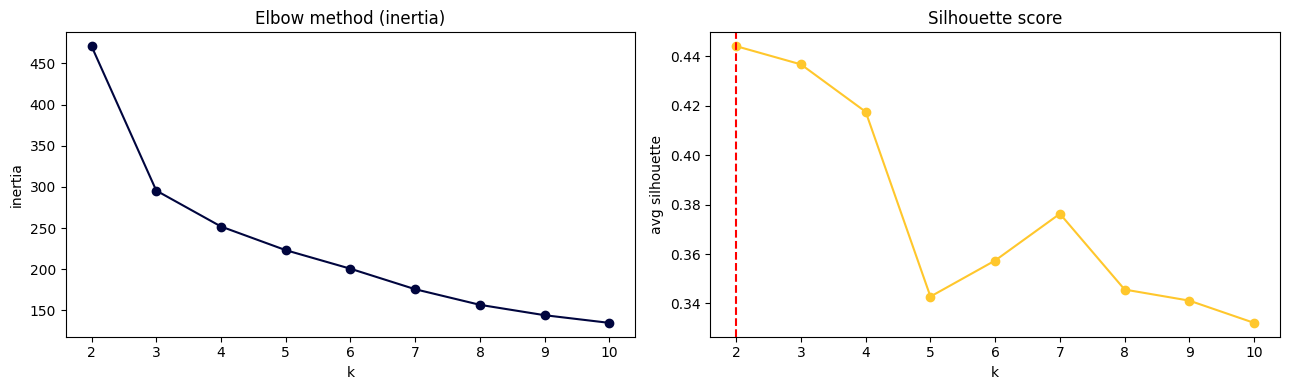

Silhouette by k: {2: np.float64(0.444), 3: np.float64(0.437), 4: np.float64(0.418), 5: np.float64(0.343), 6: np.float64(0.357), 7: np.float64(0.376), 8: np.float64(0.346), 9: np.float64(0.341), 10: np.float64(0.332)}
Best k by silhouette: 2


In [6]:
# TODO: loop over k, collect inertia and silhouette, then plot both
# Hint:
# ks = range(2, 11)
# inertias, sils = [], []
# for k in ks:
#     km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
#     inertias.append(km.inertia_)
#     sils.append(silhouette_score(Xs, km.labels_))
# then make two plots: ks vs inertias, and ks vs sils

ks = range (2,11)
inertias, sils = [],[]

for k in ks: 
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xs, km.labels_))


#ks vs inertias 

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(list(ks), inertias, "o-", color=ETSU_NAVY)
ax[0].set_title("Elbow method (inertia)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("inertia")

ax[1].plot(list(ks), sils, "o-", color=ETSU_GOLD)
ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k"); ax[1].set_ylabel("avg silhouette")


#best k 
best_k = list(ks)[int(np.argmax(sils))] 

ax[1].axvline(best_k, color="red", linestyle="--")
plt.tight_layout(); plt.show()

print("Silhouette by k:", {k: round(s, 3) for k, s in zip(ks, sils)})
print("Best k by silhouette:", best_k)


**Your chosen k and why:**

The best k is 2. Using the elbow method,  we find the place in the graph/data where inertia drops. Intertia is the total squared distance from each point to its cluster's center, measuring how close each point is. Interia will drop as k grows because more k means more centers (points will be closer to a center the more centers there are). The elbow is where the k starts dropping slower, so more clusters yield little value 

## Step 5: Fit k-means with your chosen k

In [20]:
# TODO: fit KMeans at your chosen k and attach the labels to df
# Hint: kmeans = KMeans(n_clusters=YOUR_K, random_state=42, n_init=10).fit(Xs)
# Hint: df["cluster"] = kmeans.labels_

k = 2
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
df["cluster"] = kmeans.labels_

df[["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen", "cluster"]].head(20)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,cluster
0,4181,10024,26577,1979,9194,1151,1
1,3346,4848,14310,1155,2666,1768,1
2,3687,8096,10837,870,7701,1345,1
3,3008,6327,16926,1032,5303,1582,1
4,4704,13163,20537,1507,3073,1267,1
5,6761,2802,2369,3007,1232,1204,0
6,17224,1785,3791,7407,1378,2122,0
7,4883,11831,22251,1863,4701,1580,1
8,33138,2524,5055,3119,714,3358,0
9,28125,2525,4098,5545,972,3453,0


## Step 6: Visualize the clusters with PCA

You have six features, so you cannot plot them directly. Reduce the scaled data to 2D with PCA
and color the points by cluster.

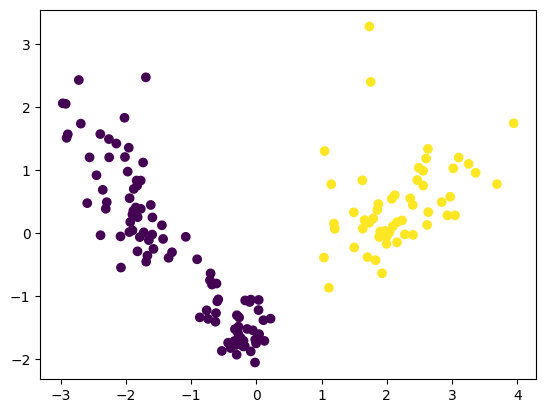

In [19]:
# TODO: project Xs to 2D with PCA and scatter it, colored by df["cluster"]
# Hint: pcs = PCA(n_components=2).fit_transform(Xs)
# Hint: plt.scatter(pcs[:,0], pcs[:,1], c=df["cluster"])

pcs = PCA(n_components=2).fit_transform(Xs)
plt.scatter(pcs[:,0], pcs[:,1], c=df["cluster"])

## Step 7: Profile and interpret the segments

Summarize each cluster by the average of each spend column (and how many customers are in it),
then describe each segment in plain words.

In [29]:
# TODO: build a profile table of per-cluster averages
# Hint: df.groupby("cluster")[spend_cols].mean().round(0)
# Hint: df["cluster"].value_counts() for the sizes

df.groupby("cluster")[spend_cols].mean().round(0)



,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,13872.0,2996.0,3373.0,3870.0,1055.0,1895.0
1,4128.0,9614.0,15824.0,1545.0,6310.0,1660.0


In [30]:
df["cluster"].value_counts()

,count
cluster,
0,95
1,55


## Step 8: Findings

1. **How many clusters did you choose, and why?** (what the elbow and silhouette showed)

Using the elbow method,  we find the place in the graph/data where inertia drops. Intertia is the total squared distance from each point to its cluster's center, measuring how close each point is. Interia will drop as k grows because more k means more centers (points will be closer to a center the more centers there are). The elbow is where the k starts dropping slower, so more clusters yield little value 

2. **Describe each segment** in plain language. What kind of customer is it (for example, a grocery-heavy retailer vs a fresh-and-frozen restaurant supplier)?

Cluster 0 spends more money on fresh and frozen produce, delicatessen, and detergents and paper products. This is likley a restaruant, or someplace that has to do meal prep. Custer 1 spends more on milk and groceries, so this is likley a business that does not need to prepare foods/things that expire quickly. 

3. **One action per segment:** what should the distributor do differently for each group?

For cluster 0, the business should promote other products that could be sold as extensions/add ons, not just part of the restarants. For cluster 1, they should offer better deals so the will buy their other products. 

4. **One limitation:** what would you want to check or try next (different k, more features, outliers)?

I would like to go through any outliers and remove them; looking at the scatterplot, there were a lot of points that seemed really far out that could have been skewed the data. I would have also liked to look at the current business plan and the deals and whatnot the business provides to customers. 

## Submission checklist

- This notebook, renamed `Lastnames_Clustering.ipynb`, all cells run with output showing